# Nonlinear mixed models with `nlmer`: orange trees and theophylline

Nonlinear mixed-effects models (NLMMs) with `nlmer()`. The model for the response is a
*nonlinear* function of a few parameters (an asymptote, a half-life, a clearance, ...) and some
of these parameters vary at random between groups:

* the **Orange** trees: a three-parameter logistic growth curve (`SSlogis`) with a random
  asymptote per tree, the Laplace approximation versus `nAGQ = 0`;
* the same model written with **user-defined model functions** that return an analytic gradient
  (the `deriv()` and hand-written `nfun2` examples of `?nlmer`);
* random effects on **more parameters**, correlated and uncorrelated;
* **fitted curves** per tree and population curve (matplotlib);
* the **Theoph** pharmacokinetic data: a one-compartment first-order model (`SSfol`) with up to
  three random effects per subject (lme4's `tests/nlmer.R`).

## Source

* lme4 help page [`?nlmer`](https://github.com/lme4/lme4/blob/master/man/nlmer.Rd)
  (local copy `upstream/lme4/man/nlmer.Rd`): examples 1–4.
* lme4's test script [`tests/nlmer.R`](https://github.com/lme4/lme4/blob/master/tests/nlmer.R)
  and its saved output `tests/nlmer.Rout.save`: the Orange model and the Theoph models
  `nm2`–`nm5` (run only at test level > 2).
* The models come from Pinheiro, J. C. and Bates, D. M. (2000), *Mixed-Effects Models in S and
  S-PLUS*, Springer (Orange: §8.2; Theoph: §8.2 and §6.4).
* **Data.** `Orange` and `Theoph` are datasets of R's base package `datasets` (Draper & Smith
  1998; Boeckmann, Sheiner & Beal 1994), not shipped with lme4. They were exported with
  `write.csv()` by `examples/r/05_nonlinear_mixed_models.R` into `examples/data/Orange.csv` and
  `examples/data/Theoph.csv`. In R both grouping factors are *ordered* factors whose levels are
  sorted by the maximum response (`Tree`: 3 < 1 < 5 < 2 < 4); the CSV does not store this, so the
  level order is restored below (it determines the order of the random effects).

The full R script is `examples/r/05_nonlinear_mixed_models.R`; it writes the reference values
used in the "Check against R" cells (`examples/reference/05_nonlinear_mixed_models.json`).
The R code reproduced here:

```r
library(lme4)
## ?nlmer
startvec <- c(Asym = 200, xmid = 725, scal = 350)
(nm1 <- nlmer(circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym|Tree,
              Orange, start = startvec))
(nm1a <- update(nm1, nAGQ = 0L))
nform <- ~Asym/(1+exp((xmid-input)/scal))
nfun <- deriv(nform, namevec=c("Asym","xmid","scal"),
              function.arg=c("input","Asym","xmid","scal"))
nm1b <- update(nm1, circumference ~ nfun(age, Asym, xmid, scal) ~ Asym | Tree)
nfun2 <- function(input, Asym, xmid, scal) {
    value <- Asym/(1+exp((xmid-input)/scal))
    grad <- cbind(Asym=1/(1+exp((xmid-input)/scal)),
              xmid=-Asym/(1+exp((xmid-input)/scal))^2*1/scal*
                    exp((xmid-input)/scal),
              scal=-Asym/(1+exp((xmid-input)/scal))^2*
                     -(xmid-input)/scal^2*exp((xmid-input)/scal))
    attr(value,"gradient") <- grad
    value
}
nm1c <- update(nm1, circumference ~ nfun2(age, Asym, xmid, scal) ~ Asym | Tree)

## more random effects
nm1d <- nlmer(circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym + xmid | Tree,
              Orange, start = startvec)
nm1u <- nlmer(circumference ~ SSlogis(age, Asym, xmid, scal) ~ (Asym|Tree) + (xmid|Tree),
              Orange, start = startvec)
nm1v <- nlmer(circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym + xmid || Tree,
              Orange, start = startvec)

## tests/nlmer.R
Th.start <- c(lKe = -2.5, lKa = 0.5, lCl = -3)
nm2 <- nlmer(conc ~ SSfol(Dose, Time,lKe, lKa, lCl) ~ (lKe+lKa+lCl|Subject),
             Theoph, start = Th.start, control = nlmerControl(tolPwrss=1e-8))
nm3 <- nlmer(conc ~ SSfol(Dose, Time,lKe, lKa, lCl) ~
                 (lKe|Subject) + (lKa|Subject) + (lCl|Subject),
             Theoph, start = Th.start)
nm4 <- nlmer(conc ~ SSfol(Dose, Time,lKe, lKa, lCl) ~ (lKa+lCl|Subject),
             Theoph, start = Th.start, control = nlmerControl(tolPwrss=1e-8))
nm5 <- nlmer(conc ~ SSfol(Dose, Time,lKe, lKa, lCl) ~ (lKa|Subject) + (lCl|Subject),
             Theoph, start = Th.start, control = nlmerControl(tolPwrss=1e-8))
```

## Setup

### How the results are compared with R

`nlmer` estimates are less reproducible than those of `lmer` or `glmer`, for two reasons that
are properties of lme4's algorithm and not of this transcription:

1. **The deviance depends on the optimizer's path.** Each evaluation of the Laplace deviance
   runs penalized nonlinear least squares (PNLS) iterations started from the conditional modes
   `u0` and fixed effects `beta0` stored in the deviance function's environment, and they stop
   at `tolPwrss`; the deviance is therefore a function of `(theta, beta)` *and* of where the
   iterations started.
2. **Nelder–Mead on a flat surface.** Both optimization stages use Nelder–Mead; rounding
   differences at the 1e-15 level change its path, and it stops wherever its simplex becomes
   small enough. With several random effects (or a variance near zero) the surface is so flat
   that it stops at points whose deviances differ in the 4th–6th significant digit; sometimes
   Python stops at a better point, sometimes R does.

The checks therefore have two parts:

* **the deviance function itself** (the core of the transcription): the deviance function of
  each model (`devFunOnly=True`) is evaluated at R's estimates, with the PNLS iterations
  started from `u = 0` in both programs; it agrees with R to `rtol = 1e-12` for **every** model;
* **the fitted model**: for the well-determined Orange model `nm1`, the log-likelihood agrees
  with `rtol = 1e-7` and the estimates with `rtol = 1e-4`; for the models with flat
  likelihood surfaces the tolerances are stated (and explained) where they are used.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.testing import assert_allclose, assert_equal

import lme4
from lme4 import nlmer, nlmerControl
from lme4.nlmer import NLValue, SSfol, SSlogis

with open("reference/05_nonlinear_mixed_models.json") as fh:
    ref = json.load(fh)
print(ref["R_version"], "| lme4", ref["lme4_version"], "| Python lme4", lme4.__version__)


def dev_at_R(formula, data, start, r, **kw):
    # The deviance function of the model (devFunOnly=True) evaluated at R's estimates,
    # with the PNLS iterations started from u = 0 (the same is done in the R script).
    devfun = nlmer(formula, data, start=start, devFunOnly=True, **kw)
    devfun.rho.u0 = np.zeros_like(devfun.rho.u0)
    par = np.atleast_1d(r["theta"])
    if kw.get("nAGQ", 1) > 0:
        par = np.concatenate([par, list(r["fixef"].values())])
    return devfun(par)


def se_RX(m):
    # standard errors from the RX-based var-cov matrix (vcov(m, use.hessian = FALSE) in R;
    # silences the warning that it differs from the Hessian-based one)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return np.sqrt(np.diag(m.vcov(use_hessian=False)))


def check_fit(m, r, ll_rtol=1e-7, est_rtol=1e-4, theta_rtol=None):
    # Compare an nlmer fit with an R reference entry (examples/r/05_nonlinear_mixed_models.R).
    assert_allclose(m.logLik().value, r["logLik"], rtol=ll_rtol)
    assert_equal(m.logLik().df, r["df"])
    assert_allclose([m.AIC(), m.BIC()], [r["AIC"], r["BIC"]], rtol=ll_rtol)
    assert_equal(list(m.fixef().index), list(r["fixef"]))
    assert_allclose(m.fixef().values, list(r["fixef"].values()), rtol=est_rtol)
    assert_allclose(m.theta, np.atleast_1d(r["theta"]), rtol=theta_rtol or est_rtol)
    assert_allclose(m.sigma(), r["sigma"], rtol=est_rtol)
    assert_allclose(se_RX(m), r["se_RX"], rtol=est_rtol)

R version 4.6.2 (2026-10-29) | lme4 2.1.0 | Python lme4 2.1.0a2


## 1. Orange trees: logistic growth with a random asymptote

`Orange` gives the trunk circumference (mm) of five orange trees at seven ages (days). The
growth curve is the three-parameter logistic

$$\text{circumference} = \frac{\text{Asym}}{1 + \exp\{(\text{xmid} - \text{age})/\text{scal}\}}$$

(`SSlogis`), with a random asymptote per tree: $\text{Asym}_i = \beta_{\text{Asym}} + b_i$.
The model is a three-part formula `response ~ nonlinear model ~ mixed part`; `start` is
required (the "self-starting" part of `SSlogis` is not used by `nlmer`).

In [2]:
Orange = pd.read_csv("data/Orange.csv")
Orange["Tree"] = pd.Categorical(Orange["Tree"].astype(str),
                                categories=ref["levels"]["Tree"], ordered=True)
Orange.head(8)

,Tree,age,circumference
0,1,118,30
1,1,484,58
2,1,664,87
3,1,1004,115
4,1,1231,120
5,1,1372,142
6,1,1582,145
7,2,118,33


In [3]:
startvec = dict(Asym=200, xmid=725, scal=350)
nm1 = nlmer("circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree",
            data=Orange, start=startvec)
print(nm1)

Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree
   Data: Orange
      AIC       BIC    logLik -2*log(L)  df.resid 
 273.1438  280.9205 -131.5719  263.1438        30 
Random effects:
 Groups   Name Std.Dev.
 Tree     Asym 31.646  
 Residual       7.843  
Number of obs: 35, groups:  Tree, 5
Fixed Effects:
 Asym   xmid   scal  
192.1  727.9  348.1  

The summary. Its standard errors come from `vcov()`, which here uses the finite-difference
Hessian (15.67, 35.41, 27.17); R's summary prints the `RX`-based values (15.58, 34.44, 26.31),
printed below the summary — see the note in "Check against R".

In [4]:
print(nm1.summary())
print("RX-based standard errors:", se_RX(nm1).round(4))

Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree
   Data: Orange

      AIC       BIC    logLik -2*log(L)  df.resid 
    273.1     280.9    -131.6     263.1        30 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.9170 -0.5421  0.1755  0.7116  1.6820 

Random effects:
 Groups   Name Variance Std.Dev.
 Tree     Asym 1001.49  31.646  
 Residual        61.51   7.843  
Number of obs: 35, groups:  Tree, 5

Fixed effects:
     Estimate Std. Error t value
Asym   192.05      15.67   12.25
xmid   727.91      35.41   20.56
scal   348.07      27.17   12.81

Correlation of Fixed Effects:
     Asym  xmid 
xmid 0.395      
scal 0.375 0.776
RX-based standard errors: [15.5839 34.4387 26.3082]


Random effects (conditional modes of the tree asymptotes) and the per-tree coefficients
`coef(nm1)` = fixed effect + random effect:

In [5]:
print(nm1.ranef())
nm1.coef()["Tree"]

$Tree
        Asym
3 -37.193563
1 -29.562236
5  -5.197201
2  31.727859
4  40.224559

with conditional variances for "Tree" 


,Asym,xmid,scal
3,154.859730,727.906397,348.073197
1,162.491056,727.906397,348.073197
5,186.856092,727.906397,348.073197
2,223.781152,727.906397,348.073197
4,232.277852,727.906397,348.073197


### Check against R

Besides the fit, the deviance function evaluated at R's estimates, the fitted values,
residuals, conditional modes and their conditional standard deviations, and the
population-level prediction `predict(nm1, re.form = NA)`.

*Standard errors.* By default `vcov()` uses the finite-difference Hessian of the deviance that
lme4 computes in its convergence checks, if it is positive definite, and otherwise falls back
to the `RX`-based estimate. Because the nlmer deviance is path dependent (see Setup), this
Hessian is noisy: in R it is not positive definite for `nm1` and R falls back to `RX` (with a
warning); in Python it happens to be positive definite, and the default standard errors differ
by about 3%. The `RX`-based values (`use_hessian=False`, `use.hessian = FALSE` in R) are
deterministic given the estimates and are compared here.

In [6]:
r = ref["nm1"]
assert_allclose(dev_at_R("circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree",
                         Orange, startvec, r), r["devAtOpt"], rtol=1e-12)
check_fit(nm1, r)
assert_allclose(nm1.deviance(), r["deviance"], rtol=1e-7)
assert_allclose(nm1.fitted().values, r["fitted"], rtol=1e-5)
assert_allclose(nm1.residuals().values, r["residuals"], atol=5e-4)  # = y - fitted; fitted agree to 1e-5
re = nm1.ranef(condVar=True)
assert_allclose(re["Tree"]["Asym"].values, r["ranef"], rtol=1e-4)
assert_allclose(np.sqrt(re["Tree"].attrs["postVar"][0, 0, :]), r["condsd"], rtol=1e-4)
for p in ["Asym", "xmid", "scal"]:
    assert_allclose(nm1.coef()["Tree"][p].values, r["coef"][p], rtol=1e-4)
assert_allclose(nm1.predict(re_form="NA").values, r["predict_NA"], rtol=1e-4)
assert_allclose(nm1.VarCorr().as_data_frame()["sdcor"].values, r["sdcor"], rtol=1e-4)
print("nm1 agrees with R")

nm1 agrees with R


### `nAGQ = 0`: the "quick and dirty" PIRLS step

With `nAGQ = 0` only the first optimization stage is run: the fixed effects are estimated by
the PNLS iterations rather than by the optimizer. Here the two fits are practically identical.

In [7]:
nm1a = nlmer("circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree",
             data=Orange, start=startvec, nAGQ=0)
print(nm1a)
pd.DataFrame({"Laplace": nm1.fixef(), "nAGQ=0": nm1a.fixef()})

Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree
   Data: Orange
      AIC       BIC    logLik -2*log(L)  df.resid 
 273.1689  280.9456 -131.5844  263.1689        30 
Random effects:
 Groups   Name Std.Dev.
 Tree     Asym 31.64   
 Residual       7.84   
Number of obs: 35, groups:  Tree, 5
Fixed Effects:
 Asym   xmid   scal  
191.1  722.6  344.2  

,Laplace,nAGQ=0
Asym,192.053293,191.059292
xmid,727.906397,722.611456
scal,348.073197,344.202043


### Check against R

θ, σ and the standard errors are compared with `rtol = 5e-4` (the fixed effects with 1e-5): on this one-dimensional problem Nelder–Mead stops at
θ = 4.0353 in Python and 4.0347 in R, where the deviance differs by 1e-7 (relative).

In [8]:
r = ref["nm1a"]
assert_allclose(dev_at_R("circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree",
                         Orange, startvec, r, nAGQ=0), r["devAtOpt"], rtol=1e-12)
check_fit(nm1a, r, est_rtol=5e-4)
assert_allclose(nm1a.fixef().values, list(r["fixef"].values()), rtol=1e-5)
assert_equal(nm1a.devcomp["dims"]["nAGQ"], 0)
print("nm1a agrees with R")

nm1a agrees with R

## 2. User-defined model functions with an analytic gradient

`nlmer` needs the gradient of the model with respect to the parameters. In R, a model function
returns its value with a `"gradient"` attribute (an n × k matrix whose columns are named after
the parameters). In Python a function called from the formula, found in the caller's namespace,
returns either an `NLValue` (an array carrying `gradient` and `gradient_names`) or a tuple
`(value, gradient)`.

**a. The `deriv()` version.** R's `deriv(~Asym/(1+exp((xmid-input)/scal)), ...)` generates a
function that computes the value and the gradient with common subexpressions. The function
below is a transcription of the code `deriv()` generates:

In [9]:
def nfun(input, Asym, xmid, scal):
    # what R's deriv(~Asym/(1+exp((xmid-input)/scal)), c("Asym","xmid","scal"),
    #                function.arg = c("input","Asym","xmid","scal")) generates
    expr3 = np.exp((xmid - input) / scal)
    expr4 = 1 + expr3
    expr8 = expr4 ** 2
    value = Asym / expr4
    grad = np.column_stack(np.broadcast_arrays(
        1 / expr4,
        -(Asym * (expr3 * (1 / scal)) / expr8),
        Asym * (expr3 * ((xmid - input) / scal ** 2)) / expr8))
    return NLValue(value, grad, ["Asym", "xmid", "scal"])


g = nfun(np.array([2.0]), 1, 3, 4).gradient
assert_allclose(g, np.atleast_2d(ref["nfun_grad"]), rtol=1e-14)   # = attr(nfun(2,1,3,4), "gradient")
g

array([[ 0.4378235 , -0.06153352,  0.01538338]])

In [10]:
nm1b = nlmer("circumference ~ nfun(age, Asym, xmid, scal) ~ Asym | Tree",
             data=Orange, start=startvec)
nm1b.fixef()

Asym    192.053293
xmid    727.906397
scal    348.073197
dtype: float64

**b. A hand-written gradient** (`nfun2` of `?nlmer`), returned as a tuple. Without column
names, the gradient columns are taken to be in the order of the parameter arguments.

In [11]:
def nfun2(input, Asym, xmid, scal):
    e = np.exp((xmid - input) / scal)
    value = Asym / (1 + e)
    grad = np.column_stack([1 / (1 + e),
                            -Asym / (1 + e) ** 2 * 1 / scal * e,
                            -Asym / (1 + e) ** 2 * -(xmid - input) / scal ** 2 * e])
    return value, grad


nm1c = nlmer("circumference ~ nfun2(age, Asym, xmid, scal) ~ Asym | Tree",
             data=Orange, start=startvec)
pd.DataFrame({"SSlogis": nm1.fixef(), "deriv()": nm1b.fixef(), "nfun2": nm1c.fixef()})

,SSlogis,deriv(),nfun2
Asym,192.053293,192.053293,192.053293
xmid,727.906397,727.906397,727.906397
scal,348.073197,348.073197,348.073197


### Check against R

The three functions compute the same model; the fits agree with R (and with each other) as
`nm1` does.

In [12]:
for name, m in [("nm1b", nm1b), ("nm1c", nm1c)]:
    check_fit(m, ref[name])
assert_allclose(nm1b.fixef().values, nm1.fixef().values, rtol=1e-6)
assert_allclose(nm1c.fixef().values, nm1.fixef().values, rtol=1e-6)
print("nm1b, nm1c agree with R")

nm1b, nm1c agree with R


## 3. Random effects on more parameters

**Correlated** random effects on the asymptote and the inflection point, `Asym + xmid | Tree`
(three covariance parameters):

In [13]:
nm1d = nlmer("circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym + xmid | Tree",
             data=Orange, start=startvec)
print(nm1d)

Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym + xmid | Tree
   Data: Orange
      AIC       BIC    logLik -2*log(L)  df.resid 
 275.7358  286.6233 -130.8679  261.7358        28 
Random effects:
 Groups   Name Std.Dev. Corr 
 Tree     Asym 34.638        
          xmid 38.391   0.77 
 Residual       7.482        
Number of obs: 35, groups:  Tree, 5
Fixed Effects:
 Asym   xmid   scal  
191.3  717.4  346.9  


**Uncorrelated** random effects: two separate terms `(Asym|Tree) + (xmid|Tree)`. The standard
deviation of `xmid` goes to (almost) zero, and the fit is that of `nm1`.

In [14]:
nm1u = nlmer("circumference ~ SSlogis(age, Asym, xmid, scal) ~ (Asym | Tree) + (xmid | Tree)",
             data=Orange, start=startvec)
print(nm1u)

Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: circumference ~ SSlogis(age, Asym, xmid, scal) ~ (Asym | Tree) + (xmid | Tree)
   Data: Orange
      AIC       BIC    logLik -2*log(L)  df.resid 
 275.1438  284.4759 -131.5719  263.1438        29 
Random effects:
 Groups   Name Std.Dev.
 Tree     Asym 31.64641
 Tree.1   xmid  0.03767
 Residual       7.84301
Number of obs: 35, groups:  Tree, 5
Fixed Effects:
 Asym   xmid   scal  
192.1  727.9  348.1  


The double-bar shortcut `Asym + xmid || Tree` is **not** the same model in `nlmer`: lme4 expands
`||` into `(1|Tree) + (0 + Asym|Tree) + (0 + xmid|Tree)` *before* `nlmer` builds its
parameter-indicator design, so an extra `(Intercept)` term appears — a random effect added
to all three parameters at once. R and Python agree on this (its estimated standard deviation
is 0); the two-term formula above is the one to use.

In [15]:
nm1v = nlmer("circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym + xmid || Tree",
             data=Orange, start=startvec)
print(nm1v)

Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym + xmid || Tree
   Data: Orange
      AIC       BIC    logLik -2*log(L)  df.resid 
 277.1129  288.0004 -131.5565  263.1129        28 
Random effects:
 Groups   Name        Std.Dev.
 Tree     (Intercept)  0.000  
 Tree.1   Asym        31.972  
 Tree.2   xmid        20.987  
 Residual              7.713  
Number of obs: 35, groups:  Tree, 5
Fixed Effects:
 Asym   xmid   scal  
191.9  726.6  347.6  


`anova()` does not support `nlmerMod` objects in R; the likelihood-ratio statistic for adding
the correlated random `xmid` (two more parameters) is computed directly. It is small:
the random asymptote is enough.

In [16]:
from scipy.stats import chi2

fits = {"nm1: Asym|Tree": nm1, "nm1u: (Asym|Tree)+(xmid|Tree)": nm1u,
        "nm1d: Asym+xmid|Tree": nm1d}
print(pd.DataFrame({"npar": [m.logLik().df for m in fits.values()],
                    "AIC": [m.AIC() for m in fits.values()],
                    "BIC": [m.BIC() for m in fits.values()],
                    "logLik": [m.logLik().value for m in fits.values()]},
                   index=list(fits)).round(4))
lrt = 2 * (nm1d.logLik().value - nm1.logLik().value)
print(f"\nLRT nm1d vs nm1: Chisq = {lrt:.4f}, df = 2, p = {chi2.sf(lrt, 2):.3f}")

                               npar       AIC       BIC    logLik
nm1: Asym|Tree                    5  273.1438  280.9205 -131.5719
nm1u: (Asym|Tree)+(xmid|Tree)     6  275.1438  284.4759 -131.5719
nm1d: Asym+xmid|Tree              7  275.7358  286.6233 -130.8679

LRT nm1d vs nm1: Chisq = 1.4080, df = 2, p = 0.495


### Check against R

These surfaces are flat, and Nelder–Mead stops at different points in R and in Python:

* `nm1u`: the extra standard deviation is near zero (Python 0.038, R 0.131 — both
  practically zero on the scale of `xmid` ≈ 728); the log-likelihoods agree to 2e-7 and the
  fixed effects to 1e-4. θ is compared only for `Asym`.
* `nm1d`: Python's optimum is slightly *better* than R's (log-likelihood higher by 1.3e-3,
  relative 1e-5); θ differs by up to 10%, the fixed effects by 3e-4.
* `nm1v`: R stops at a worse point (its log-likelihood equals `nm1`'s, with the `xmid` standard
  deviation stuck at 0.0018); Python finds a log-likelihood 0.015 higher with a standard
  deviation of 21 for `xmid`.

The deviance *function* agrees with R to 1e-12 for all three models; at the optimum we assert
that Python's log-likelihood is at least as good as R's (within 2e-7, relative), with stated
tolerances.

In [17]:
forms = {"nm1d": "Asym + xmid | Tree", "nm1u": "(Asym | Tree) + (xmid | Tree)",
         "nm1v": "Asym + xmid || Tree"}
for name, m in [("nm1d", nm1d), ("nm1u", nm1u), ("nm1v", nm1v)]:
    r = ref[name]
    f = "circumference ~ SSlogis(age, Asym, xmid, scal) ~ " + forms[name]
    assert_allclose(dev_at_R(f, Orange, startvec, r), r["devAtOpt"], rtol=1e-12)
    assert_equal(m.logLik().df, r["df"])
    assert m.logLik().value >= r["logLik"] * (1 + 2e-7), name
    print(f"{name}: logLik Python - R = {m.logLik().value - r['logLik']:.2e}")

r = ref["nm1u"]
assert_allclose(nm1u.logLik().value, r["logLik"], rtol=2e-7)
assert_allclose(nm1u.fixef().values, list(r["fixef"].values()), rtol=1e-4)
assert_allclose(nm1u.theta[0], r["theta"][0], rtol=1e-4)
assert_allclose(nm1u.sigma(), r["sigma"], rtol=1e-4)
r = ref["nm1d"]
assert_allclose(nm1d.logLik().value, r["logLik"], rtol=2e-5)
assert_allclose(nm1d.fixef().values, list(r["fixef"].values()), rtol=1e-3)
assert_allclose(nm1d.theta, r["theta"], rtol=0.15)
assert_allclose(lrt, ref["lrt"]["d_vs_1"], atol=5e-3)
r = ref["nm1v"]
assert_equal(list(nm1v.VarCorr().as_data_frame()["var1"].iloc[:3]), r["var1"][:3])
assert_allclose(nm1v.logLik().value, r["logLik"], rtol=2e-4)
assert_allclose(nm1v.fixef().values, list(r["fixef"].values()), rtol=5e-3)
print("nm1d, nm1u, nm1v agree with R (within the stated tolerances)")

nm1d: logLik Python - R = 1.33e-03
nm1u: logLik Python - R = -1.81e-05


nm1v: logLik Python - R = 1.54e-02
nm1d, nm1u, nm1v agree with R (within the stated tolerances)


## 4. Fitted growth curves

`predict(newdata = ...)` is not available for `nlmer` fits in R (`predict(nm1, newdata)` fails
with *object 'Asym' not found*, and `re.form = NA` only returns `X %*% beta`), so the fitted
curves are drawn by evaluating the model function at the per-tree coefficients `coef(nm1)`
(solid lines) and at the fixed effects (the population curve, dashed). At the observed ages the
curves pass through `fitted(nm1)`.

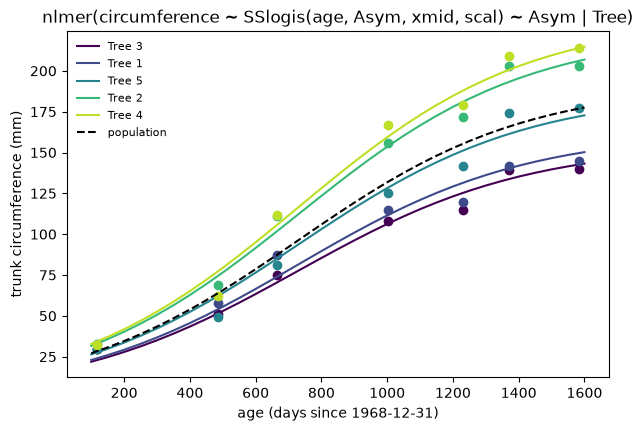

In [18]:
grid = np.arange(100.0, 1601.0, 50.0)
cf = nm1.coef()["Tree"]
curves = {tree: np.asarray(SSlogis(grid, p.Asym, p.xmid, p.scal)) for tree, p in cf.iterrows()}
fe = nm1.fixef()

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(cf)))
for (tree, curve), col in zip(curves.items(), colors):
    d = Orange[Orange["Tree"] == tree]
    ax.plot(d["age"], d["circumference"], "o", color=col)
    ax.plot(grid, curve, "-", color=col, label=f"Tree {tree}")
ax.plot(grid, SSlogis(grid, fe["Asym"], fe["xmid"], fe["scal"]), "k--", label="population")
ax.set_xlabel("age (days since 1968-12-31)")
ax.set_ylabel("trunk circumference (mm)")
ax.set_title("nlmer(circumference ~ SSlogis(age, Asym, xmid, scal) ~ Asym | Tree)")
ax.legend(frameon=False, fontsize=8)
plt.show()

# at the observed ages the curves reproduce fitted(nm1)
obs = np.concatenate([SSlogis(Orange.loc[Orange["Tree"] == t, "age"].to_numpy(), *cf.loc[t])
                      for t in Orange["Tree"].unique()])
assert_allclose(obs, nm1.fitted().values, rtol=1e-10)

### Check against R

The curves computed in R with `SSlogis(grid, Asym, xmid, scal)` from `coef(nm1)`:

In [19]:
for tree, curve in curves.items():
    assert_allclose(curve, ref["curves"][tree], rtol=1e-4)
print("curves agree with R")

curves agree with R


## 5. Theophylline pharmacokinetics (`tests/nlmer.R`)

`Theoph`: serum concentration of theophylline (mg/L) in 12 subjects over 25 hours after an
oral dose (mg/kg). The first-order one-compartment model `SSfol(Dose, Time, lKe, lKa, lCl)`

$$C(t) = \frac{D\, e^{\text{lKe} + \text{lKa} - \text{lCl}}}{e^{\text{lKa}} - e^{\text{lKe}}}
\left(e^{-e^{\text{lKe}} t} - e^{-e^{\text{lKa}} t}\right)$$

has the log elimination rate constant, log absorption rate constant and log clearance as
parameters. lme4's test script fits four random-effects structures.

In [20]:
Theoph = pd.read_csv("data/Theoph.csv")
Theoph["Subject"] = pd.Categorical(Theoph["Subject"].astype(str),
                                   categories=ref["levels"]["Subject"], ordered=True)
Th_start = dict(lKe=-2.5, lKa=0.5, lCl=-3)
ctrl = nlmerControl(tolPwrss=1e-8)
TH = "conc ~ SSfol(Dose, Time, lKe, lKa, lCl) ~ "
th_models = {
    "nm2": ("(lKe + lKa + lCl | Subject)", dict(control=ctrl)),
    "nm3": ("(lKe | Subject) + (lKa | Subject) + (lCl | Subject)", {}),
    "nm4": ("(lKa + lCl | Subject)", dict(control=ctrl)),     # dropping lKe
    "nm5": ("(lKa | Subject) + (lCl | Subject)", dict(control=ctrl)),
}
th_fits = {}
for name, (re_part, kw) in th_models.items():
    th_fits[name] = nlmer(TH + re_part, data=Theoph, start=Th_start, **kw)
    print(f"--- {name}")
    print(th_fits[name])

--- nm2
Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: conc ~ SSfol(Dose, Time, lKe, lKa, lCl) ~ (lKe + lKa + lCl | Subject)
   Data: Theoph
      AIC       BIC    logLik -2*log(L)  df.resid 
  366.490   395.318  -173.245   346.490       122 
Random effects:
 Groups   Name Std.Dev. Corr        
 Subject  lKe  0.1307               
          lKa  0.6563    0.03       
          lCl  0.2519    0.99 -0.08 
 Residual      0.6797               
Number of obs: 132, groups:  Subject, 12
Fixed Effects:
    lKe      lKa      lCl  
-2.4478   0.4744  -3.2198  


--- nm3
Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: conc ~ SSfol(Dose, Time, lKe, lKa, lCl) ~ (lKe | Subject) + (lKa | Subject) + (lCl | Subject)
   Data: Theoph
      AIC       BIC    logLik -2*log(L)  df.resid 
 367.9841  388.1637 -176.9920  353.9841       125 
Random effects:
 Groups    Name Std.Dev. 
 Subject   lKe  2.857e-06
 Subject.1 lKa  6.593e-01
 Subject.2 lCl  1.675e-01
 Residual       7.075e-01
Number of obs: 132, groups:  Subject, 12
Fixed Effects:
    lKe      lKa      lCl  
-2.4656   0.4847  -3.2303  


--- nm4
Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: conc ~ SSfol(Dose, Time, lKe, lKa, lCl) ~ (lKa + lCl | Subject)
   Data: Theoph
      AIC       BIC    logLik -2*log(L)  df.resid 
 367.9808  388.1604 -176.9904  353.9808       125 
Random effects:
 Groups   Name Std.Dev. Corr  
 Subject  lKa  0.6559         
          lCl  0.1675   -0.01 
 Residual      0.7078         
Number of obs: 132, groups:  Subject, 12
Fixed Effects:
    lKe      lKa      lCl  
-2.4656   0.4816  -3.2304  


--- nm5
Nonlinear mixed model fit by maximum likelihood  ['nlmerMod']
Formula: conc ~ SSfol(Dose, Time, lKe, lKa, lCl) ~ (lKa | Subject) + (lCl | Subject)
   Data: Theoph
      AIC       BIC    logLik -2*log(L)  df.resid 
 365.9838  383.2806 -176.9919  353.9838       126 
Random effects:
 Groups    Name Std.Dev.
 Subject   lKa  0.6614  
 Subject.1 lCl  0.1673  
 Residual       0.7073  
Number of obs: 132, groups:  Subject, 12
Fixed Effects:
    lKe      lKa      lCl  
-2.4654   0.4859  -3.2302  


In [21]:
pd.DataFrame({name: {"npar": m.logLik().df, "logLik": m.logLik().value,
                     "AIC": m.AIC(), "BIC": m.BIC(), **m.fixef().to_dict()}
              for name, m in th_fits.items()}).T.round(4)

,npar,logLik,AIC,BIC,lKe,lKa,lCl
nm2,10.0,-173.2450,366.4900,395.3180,-2.4478,0.4744,-3.2198
nm3,7.0,-176.9920,367.9841,388.1637,-2.4656,0.4847,-3.2303
nm4,7.0,-176.9904,367.9808,388.1604,-2.4656,0.4816,-3.2304
nm5,6.0,-176.9919,365.9838,383.2806,-2.4654,0.4859,-3.2302


The random effect on `lKe` is not supported by the data (its standard deviation is near zero
in `nm3`, and `nm4`/`nm5` without it have practically the same likelihood as `nm3`). Fitted
concentration curves of `nm5` for each subject, from `coef(nm5)` and each subject's dose:

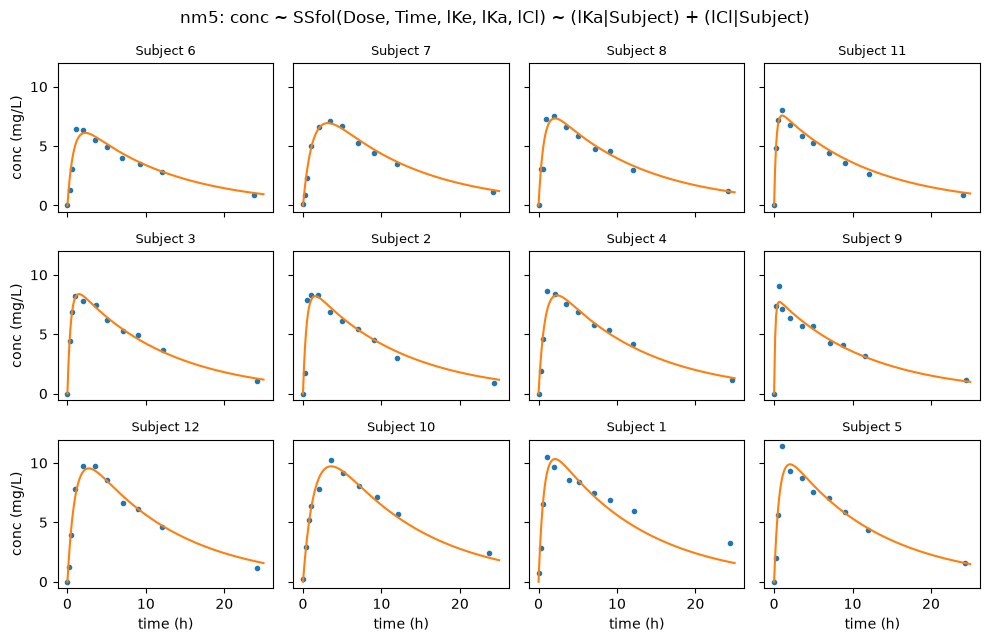

In [22]:
nm5 = th_fits["nm5"]
cf5 = nm5.coef()["Subject"]
tgrid = np.linspace(0, 25, 200)
fig, axes = plt.subplots(3, 4, figsize=(10, 6.5), sharex=True, sharey=True)
for ax, subj in zip(axes.flat, cf5.index):
    d = Theoph[Theoph["Subject"] == subj]
    p = cf5.loc[subj]
    ax.plot(d["Time"], d["conc"], "o", ms=3, color="C0")
    ax.plot(tgrid, SSfol(d["Dose"].iloc[0], tgrid, p.lKe, p.lKa, p.lCl), color="C1")
    ax.set_title(f"Subject {subj}", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time (h)")
for ax in axes[:, 0]:
    ax.set_ylabel("conc (mg/L)")
fig.suptitle("nm5: conc ~ SSfol(Dose, Time, lKe, lKa, lCl) ~ (lKa|Subject) + (lCl|Subject)")
fig.tight_layout()
plt.show()

### Check against R

The deviance functions agree with R to 1e-12. The optima are on flat surfaces and differ in
the way described in Setup:

| model | logLik Python − R | note |
|---|---|---|
| `nm2` | +0.026 | 6 covariance parameters; R stops earlier (Python's optimum is better) |
| `nm3` | −3e-5 | `lKe` standard deviation ≈ 0 (Python 0, R 0.0009) |
| `nm4` | +2.4e-4 | near-singular correlation |
| `nm5` | −7e-4 | R's optimum is slightly better |

So the log-likelihoods are compared with `rtol = 2e-4`, the fixed effects (on the log scale)
with `atol = 0.03`, the residual standard deviation and the `RX`-based standard errors with
`rtol = 3e-2`.

In [23]:
for name, m in th_fits.items():
    r = ref[name]
    re_part, kw = th_models[name]
    assert_allclose(dev_at_R(TH + re_part, Theoph, Th_start, r, **kw), r["devAtOpt"],
                    rtol=1e-12)
    assert_equal(m.logLik().df, r["df"])
    assert_equal(list(m.fixef().index), list(r["fixef"]))
    assert_allclose(m.logLik().value, r["logLik"], rtol=2e-4)
    assert_allclose(m.fixef().values, list(r["fixef"].values()), atol=0.03)
    assert_allclose(m.sigma(), r["sigma"], rtol=3e-2)
    assert_allclose(se_RX(m), r["se_RX"], rtol=3e-2)
    print(f"{name}: logLik Python - R = {m.logLik().value - r['logLik']:+.2e}")
for p in ["lKe", "lKa", "lCl"]:
    assert_allclose(cf5[p].values, ref["nm5"]["coef"][p], atol=0.03)
assert_allclose(nm5.fitted().values, ref["nm5"]["fitted"], rtol=2e-2, atol=1e-2)
print("Theoph models agree with R (within the stated tolerances)")

nm2: logLik Python - R = +2.61e-02


nm3: logLik Python - R = -2.95e-05


nm4: logLik Python - R = +2.40e-04


nm5: logLik Python - R = -6.91e-04
Theoph models agree with R (within the stated tolerances)


## Summary

* `nlmer()` reproduces lme4's nonlinear mixed models with self-starting models (`SSlogis`,
  `SSfol`, ...) and user-defined model functions with analytic gradients.
* The Laplace deviance function is identical to R's (to 1e-12 at the same parameters and
  starting state). For the well-determined Orange model the fit agrees with R to 1e-7 in the
  log-likelihood and 1e-4 in the estimates.
* With several random effects the nlmer likelihood surfaces are flat and Nelder–Mead stops at
  points that differ between R and Python in the 4th–6th digit of the log-likelihood (in either
  direction); the variance parameters can then differ substantially. This is the same
  sensitivity R shows when, for example, the starting values or the platform change.
* `predict(newdata=)` is not available for `nlmer` fits (in R either); curves are computed from
  `coef()` and the model function.